# 60_compare: model comparison and EOL-alarm sensitivity

**Owner:** Khải Hưng · **Review:** Quốc Đạt · **Plan:** `docs/Go.md` GĐ7, WBS C4.1, protocol in `docs/Rec.md` 6 and 6.1.

Code lives in `src/compare_models.py`; this notebook runs it and shows the tables and figures used in Report §5.8.
Inputs are the seven prediction files in `reports/predictions/` (naive, regression, arima/arimax, svr, lstm, hybrid), each checked by `protocol.check_pred`.
`hybrid` is the fifth model (`notebooks/70_hybrid.ipynb`, design in `docs/Rec.md` section 8). It was designed **after** the first four models had been scored,
with every choice made by cross-validation on the training cells, and it was run on the test cells once.

## Step 1. Run the comparison

In [1]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import compare_models as C

out = C.main()
pd.set_option("display.precision", 4)

## Step 2. Forecast accuracy on the four test cells (213 rows per scenario)

E1 = one step ahead on the last 40% of each test cell. E2 = multi-step from the 60% origin with no observed SOH after the origin.
`PI_coverage` is the share of rows inside the model's interval, where a model exports one (nominal 95%).

**How the models are fitted differs.** Regression, SVR and LSTM learn from the 8 training cells and are applied to the test cells.
ARIMA and ARIMAX are fitted on the first 60% **of each test cell itself** (RQ3: forecasting from a cell's own history), so they see that cell's own early fade.
The hybrid combines both: a prior curve learned from the 8 training cells, updated with the test cell's own first 60%.
Naive uses only the previous (E1) or origin (E2) value. The scores are on the same 213 rows, but this difference must be stated next to any comparison table.

In [2]:
out['pooled']

,model,scenario,n,MAE,RMSE,MAPE_pct,R2,PI_coverage
8,naive,E1,213,0.0119,0.0226,1.4288,0.5001,NaN
10,regression,E1,213,0.0116,0.0226,1.3953,0.5011,NaN
0,arima,E1,213,0.0114,0.0203,1.3851,0.5981,0.9014
2,arimax,E1,213,0.0098,0.0171,1.1820,0.7145,0.9202
12,svr,E1,213,0.0102,0.0172,1.2225,0.7091,0.9108
6,lstm,E1,213,0.0098,0.0190,1.1783,0.6467,NaN
4,hybrid,E1,213,0.0115,0.0226,1.3824,0.5001,0.9014
9,naive,E2,213,0.0249,0.0343,3.1271,-0.1552,NaN
11,regression,E2,213,0.0330,0.0446,4.1235,-0.9526,NaN
1,arima,E2,213,0.0468,0.0594,5.7882,-2.4560,0.7089


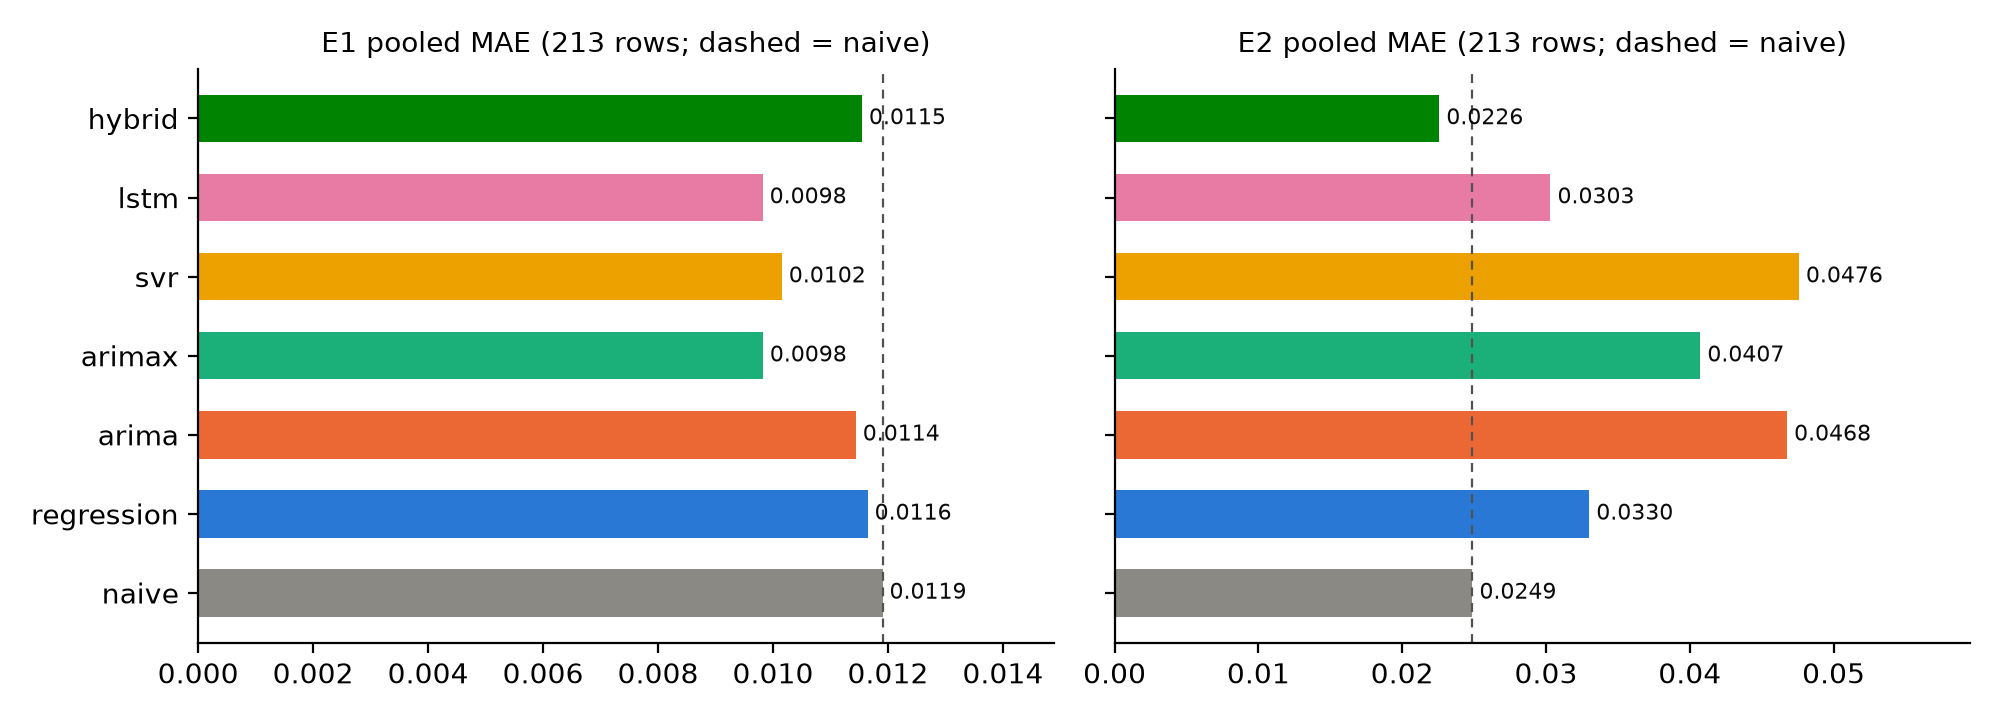

In [3]:
display(Image(str(ROOT / 'reports/figures/compare_mae.png')))

**Reading.**
- **E1:** every model beats naive (MAE 0.0119), but the gain is small: the best (LSTM, ARIMAX) reach 0.0098, about 18% lower. Regression (0.0116) and the hybrid (0.0115)
  are close to naive because both start each forecast from the previous observed SOH.
- **E2:** the **hybrid is the only model below naive** (MAE 0.0226 vs 0.0249, about 9% lower; RMSE 0.0325 vs 0.0343). The Diebold–Mariano test (`reports/tables/hybrid_dm_tests.csv`)
  does **not** find this difference significant (p = 0.59); against LSTM, the best of the first four models in E2 (0.0303), the hybrid is significantly better (p < 0.001).
- The four original models all lose to naive in E2. Naive wins on MAE because SOH changes slowly and three test cells are almost flat after the origin, not because a flat line is a useful forecast (see Step 4).
- Intervals: ARIMA/ARIMAX cover about 90–92% in E1 but only 71% in E2; the hybrid covers 90.1% in E1 and 85.0% in E2. All are below the nominal 95%.

Per-cell MAE (E2 R² is strongly negative where the tail has little variation, e.g. B0034):

In [4]:
out['per_cell'].pivot_table(index=['scenario','battery_id'], columns='model', values='MAE')[C.MODELS]

model                 naive  regression   arima  arimax     svr    lstm  \
scenario battery_id                                                       
E1       B0007       0.0028      0.0026  0.0068  0.0031  0.0036  0.0018   
         B0034       0.0085      0.0085  0.0074  0.0076  0.0081  0.0064   
         B0047       0.0102      0.0091  0.0083  0.0074  0.0094  0.0059   
         B0055       0.0349      0.0348  0.0293  0.0271  0.0257  0.0327   
E2       B0007       0.0452      0.0560  0.0348  0.0371  0.0298  0.0294   
         B0034       0.0124      0.0145  0.0596  0.0143  0.0774  0.0323   
         B0047       0.0167      0.0332  0.0736  0.0636  0.0305  0.0378   
         B0055       0.0209      0.0304  0.0229  0.0823  0.0313  0.0228   

model                hybrid  
scenario battery_id          
E1       B0007       0.0025  
         B0034       0.0085  
         B0047       0.0086  
         B0055       0.0348  
E2       B0007       0.0115  
         B0034       0.0215  
         B0047       0.0464  
         B0055       0.0265

The hybrid's E2 gain comes from B0007, the cell that keeps fading steadily (MAE 0.0115 vs 0.0452 for naive). On the three almost-flat cells naive is better
(B0034 0.0215 vs 0.0124, B0047 0.0464 vs 0.0167, B0055 0.0265 vs 0.0209).

## Step 3. Remaining useful life (E2)

`rul_error = eol_pred − eol_true` in cycles (negative = warns early, positive = warns late). Blank `eol_pred` = the forecast never drops below 0.8.
B0047 is excluded because it crossed 0.8 before the origin (Rec.md 6.1 #3). B0034 (min SOH 0.799) and B0055 (min 0.791) only just cross the threshold.

In [5]:
out['rul'].pivot_table(index='model', columns='battery_id', values='rul_error').reindex(C.MODELS)

battery_id,B0007,B0034,B0055
model,,,
naive,NaN,NaN,NaN
regression,-14.0,NaN,26.0
arima,-12.0,-49.0,NaN
arimax,-11.0,NaN,6.0
svr,-14.0,-58.0,22.0
lstm,-8.0,-36.0,NaN
hybrid,-4.0,-19.0,32.0


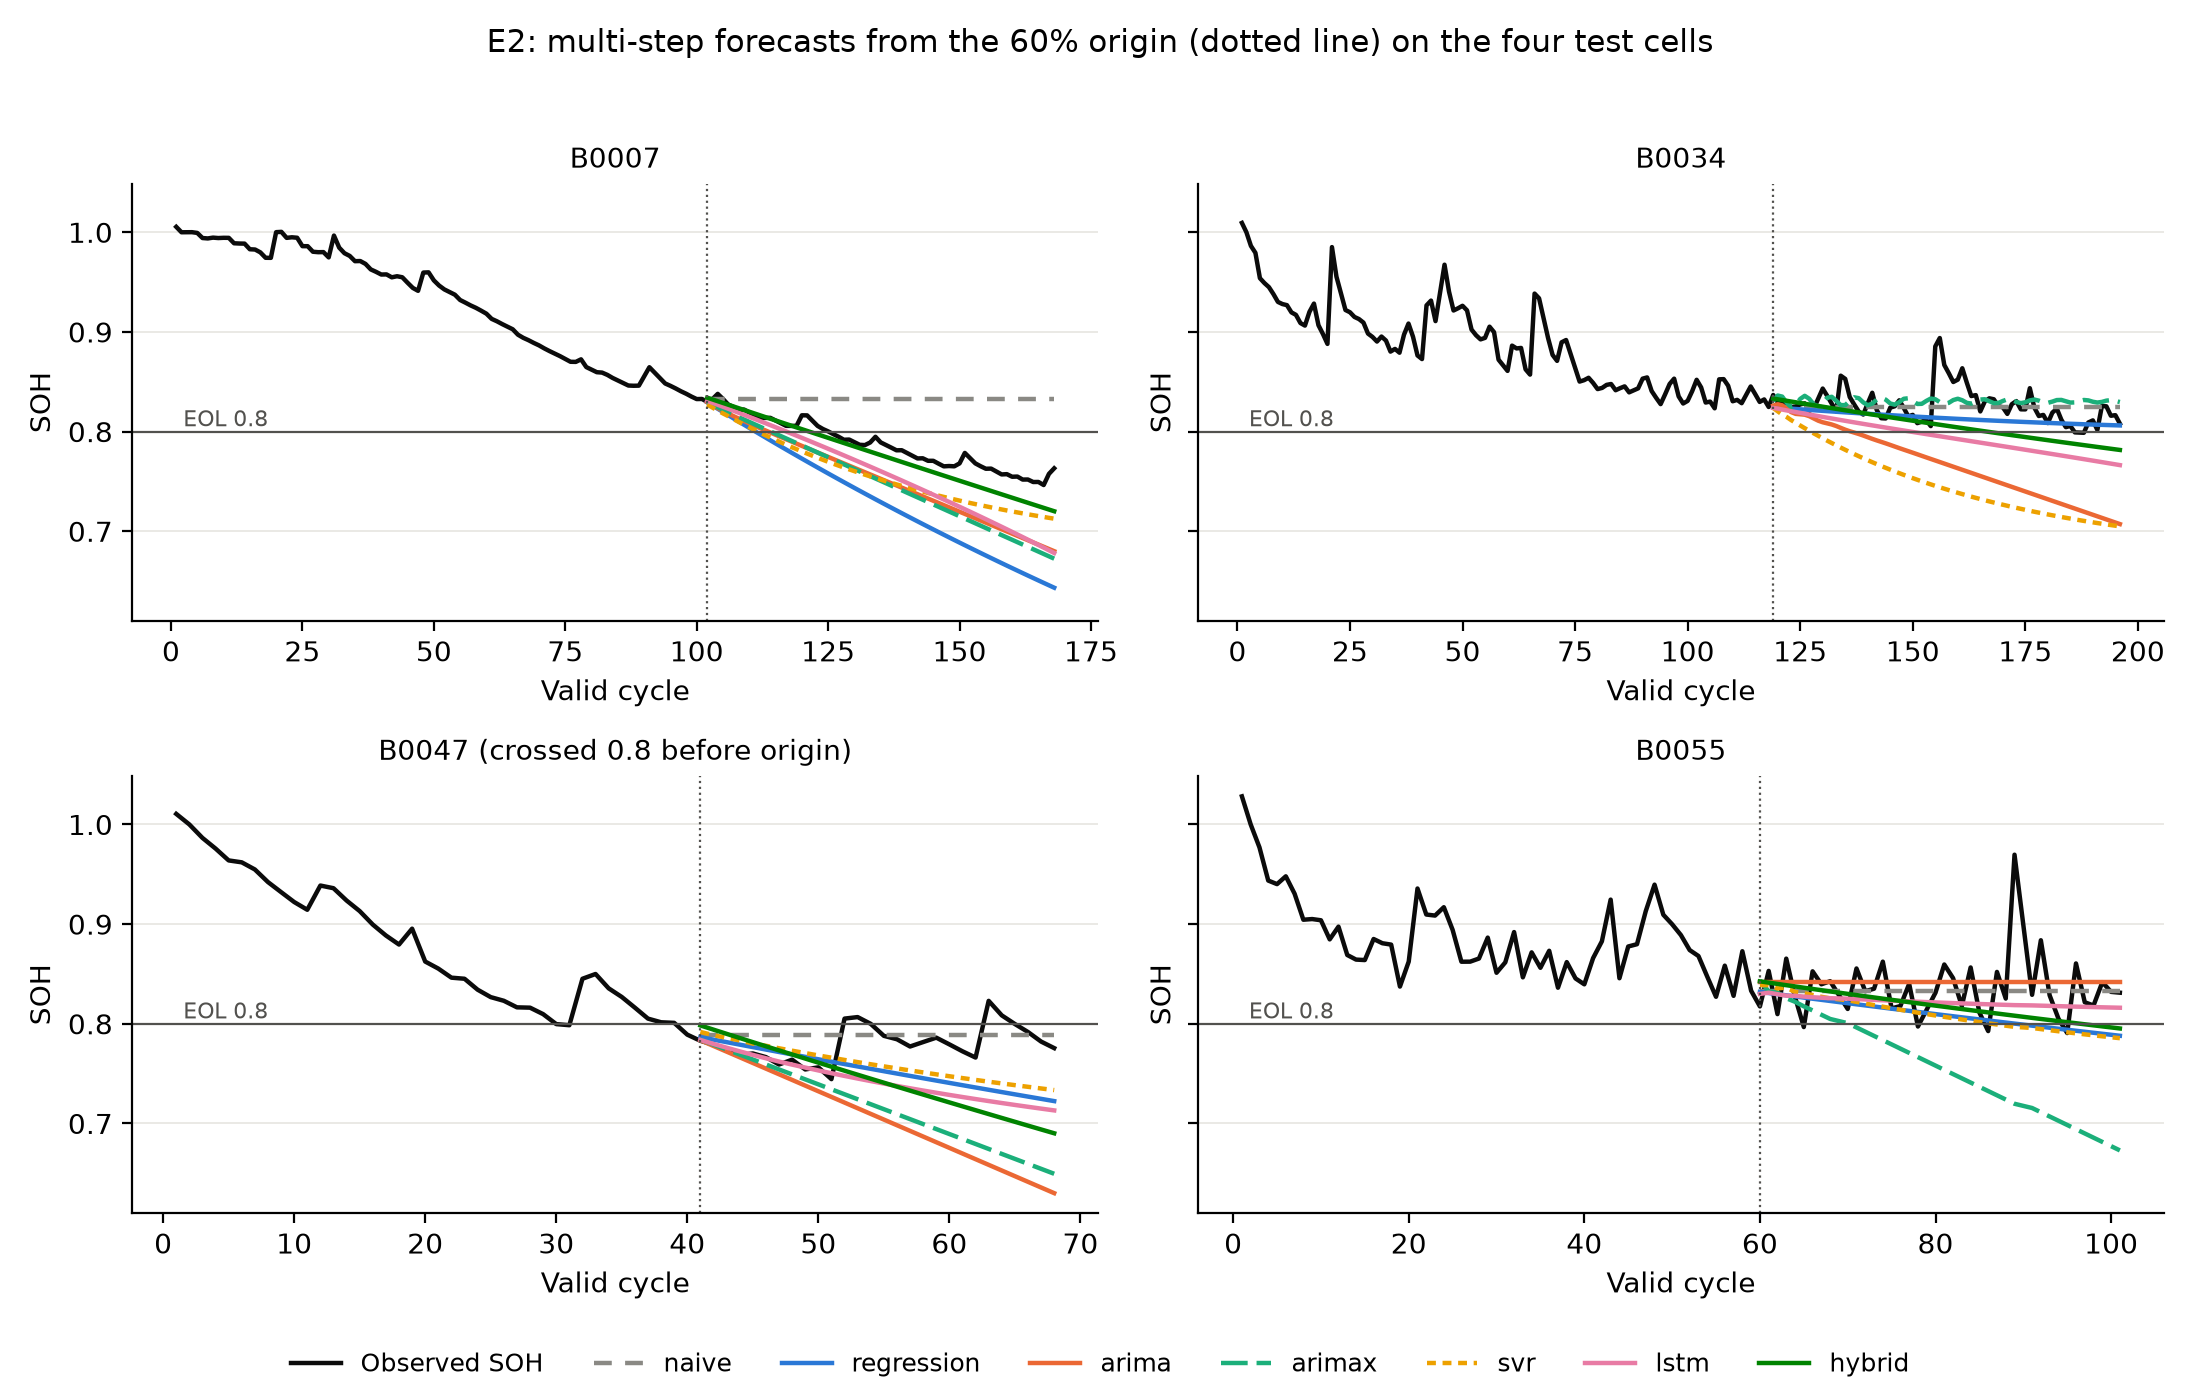

In [6]:
display(Image(str(ROOT / 'reports/figures/compare_e2_forecasts.png')))

**Reading.** Naive never predicts EOL. Only the hybrid and SVR reach 0.8 on all three cells. The hybrid has the smallest error on B0007 (−4 cycles) and on B0034 (−19),
but is late on B0055 (+32), where ARIMAX is best (+6) while missing B0034. No model is best on all three cells, and with three cells the RUL comparison is descriptive only.

## Step 4. EOL alarm: sensitivity and specificity (Chap 4)

**Question for a fleet or warranty operator:** at cycle *t*, will this cell fall below SOH 0.8 within the next 20 cycles?

- **Decision rows:** every E2 evaluation cycle *t* of B0007, B0034 and B0055 before the true crossing. Rows where the window runs past the last observed cycle without an observed crossing are dropped (label unknown). The same 96 rows are used for every model.
- **True label:** the first observed cycle with SOH < 0.8 lies in (*t*, *t* + 20].
- **Alarm:** the model's first predicted crossing on its E2 trajectory is at or before *t* + 20.
- Positive class = "EOL within 20 cycles". Sensitivity = share of real upcoming EOLs that raised an alarm; specificity = share of safe cycles with no alarm.

In [7]:
out['alarm']

,model,TP,FN,FP,TN,sensitivity,specificity,precision,accuracy
0,naive,0,45,0,51,0.0000,1.0000,NaN,0.5312
1,regression,20,25,4,47,0.4444,0.9216,0.8333,0.6979
2,arima,40,5,51,0,0.8889,0.0000,0.4396,0.4167
3,arimax,25,20,4,47,0.5556,0.9216,0.8621,0.7500
4,svr,40,5,51,0,0.8889,0.0000,0.4396,0.4167
5,lstm,40,5,40,11,0.8889,0.2157,0.5000,0.5312
6,hybrid,40,5,23,28,0.8889,0.5490,0.6349,0.7083


Robustness to the horizon (10, 20, 30 cycles):

In [8]:
out['horizons'].pivot_table(index='model', columns='horizon', values=['sensitivity','specificity']).reindex(C.MODELS).round(3)

sensitivity               specificity              
horizon             10     20     30          10     20     30
model                                                         
naive             0.00  0.000  0.000       1.000  1.000  1.000
regression        0.40  0.444  0.475       0.803  0.922  1.000
arima             0.80  0.889  0.915       0.141  0.000  0.000
arimax            0.56  0.556  0.492       0.845  0.922  1.000
svr               0.80  0.889  1.000       0.000  0.000  0.000
lstm              0.80  0.889  0.915       0.380  0.216  0.027
hybrid            0.80  0.889  0.915       0.676  0.549  0.486

**Reading.**
- **Naive has sensitivity 0**: it never raises an alarm, so its E2 MAE advantage has no value for maintenance decisions.
- **ARIMA, SVR and LSTM** catch most upcoming EOLs (sensitivity 0.89) but alarm too early: their E2 trajectories fall faster than the real cells, so most safe cycles also get an alarm (specificity 0.00–0.22).
- **Regression and ARIMAX** are the opposite trade-off: few false alarms (specificity 0.92) but miss about half of the upcoming EOLs (sensitivity 0.44–0.56): both never reach 0.8 on B0034, and regression also crosses 26 cycles late on B0055.
- **The hybrid** keeps the sensitivity of the first group (0.89) with clearly fewer false alarms (specificity 0.55, precision 0.64): the best balance among the models that catch most EOLs. Its 5 misses are on B0055, where it crosses late.
- The pattern holds for 10-, 20- and 30-cycle horizons (hybrid sensitivity / specificity: 0.80 / 0.68, 0.89 / 0.55, 0.92 / 0.49).

**Caveat.** The 96 rows come from only three cells and are strongly dependent (consecutive cycles of one trajectory), so these rates describe these cells, not a population; each miss or false alarm is driven by one cell's predicted crossing time. The alarm uses the fixed-origin E2 trajectory, i.e. a plan made at the origin; a deployed system would re-forecast every cycle.

## Step 5. Summary for Report §5.8

| Criterion | Best | Note |
|---|---|---|
| E1 one-step accuracy | LSTM, ARIMAX (MAE 0.0098) | All models beat naive, by at most ~18% |
| E2 multi-step accuracy | Hybrid (MAE 0.0226), then naive (0.0249) | Hybrid vs naive not significant (DM p = 0.59); the four original models lose to naive |
| RUL error | Hybrid on B0007 (−4) and B0034 (−19); ARIMAX on B0055 (+6) | No model best on all three cells |
| EOL alarm | Hybrid: sensitivity 0.89 with specificity 0.55 | Regression/ARIMAX: specific but miss half; ARIMA/SVR/LSTM: sensitive but alarm too early; naive never alarms |

ARIMA/ARIMAX are fitted on each test cell's own first 60%; regression, SVR and LSTM learn from the 8 training cells; the hybrid uses both (Step 2).
The replacement-cost analysis of the alarms is in `notebooks/70_hybrid.ipynb`.

Outputs: `reports/tables/compare_*.csv`, `reports/figures/compare_mae.png`, `reports/figures/compare_e2_forecasts.png`.